In [2]:
import sys
from pathlib import Path

import pandas as pd

print("Python:", sys.executable)
print("Working folder:", Path.cwd())

Python: c:\Users\clarkb\Documents\movie-recommendation-system\.venv\Scripts\python.exe
Working folder: c:\Users\clarkb\Documents\movie-recommendation-system\notebooks


In [3]:
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data" / "raw" / "ml-latest-small"

movies = pd.read_csv(data_dir / "movies.csv")
ratings = pd.read_csv(data_dir / "ratings.csv")

In [4]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [6]:
print("Movies table shape:", movies.shape)
print("Ratings table shape:", ratings.shape)

print("Unique users:", ratings["userId"].nunique())
print("Unique rated movies:", ratings["movieId"].nunique())

Movies table shape: (9742, 3)
Ratings table shape: (100836, 4)
Unique users: 610
Unique rated movies: 9724


In [7]:
has_rating = movies["movieId"].isin(ratings["movieId"])

movies_without_ratings = movies.loc[~has_rating]

print("Movies without ratings:", len(movies_without_ratings))

movies_without_ratings.head()

Movies without ratings: 18


,movieId,title,genres
816,1076,"Innocents, The (1961)",Drama|Horror|Thriller
2211,2939,Niagara (1953),Drama|Thriller
2499,3338,For All Mankind (1989),Documentary
2587,3456,"Color of Paradise, The (Rang-e khoda) (1999)",Drama
3118,4194,I Know Where I'm Going! (1945),Drama|Romance|War


In [8]:
movies.isna().sum()

movieId    0
title      0
genres     0
dtype: int64

In [9]:
ratings.isna().sum()

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

In [10]:
print(
    "Duplicate movie IDs:",
    movies["movieId"].duplicated().sum()
)

print(
    "Duplicate rating rows:",
    ratings.duplicated().sum()
)

print(
    "Repeated user-movie pairs:",
    ratings.duplicated(subset=["userId", "movieId"]).sum()
)

Duplicate movie IDs: 0
Duplicate rating rows: 0
Repeated user-movie pairs: 0


In [11]:
print("Movies — missing values:")
print(movies.isna().sum())

print("Ratings — missing values:")
print(ratings.isna().sum())

Movies — missing values:
movieId    0
title      0
genres     0
dtype: int64
Ratings — missing values:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [12]:
rating_counts = ratings["rating"].value_counts().sort_index()

rating_counts

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64

In [13]:
movie_ids_match = ratings["movieId"].isin(movies["movieId"])

print(
    "Ratings with no matching catalog movie:",
    (~movie_ids_match).sum()
)

Ratings with no matching catalog movie: 0


In [14]:
ratings_with_movies = ratings.merge(
    movies,
    on="movieId",
    how="left",
    validate="many_to_one"
)

ratings_with_movies.head()

,userId,movieId,rating,timestamp,title,genres
0,1,1,4.0,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.0,964982224,Heat (1995),Action|Crime|Thriller
3,1,47,5.0,964983815,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,5.0,964982931,"Usual Suspects, The (1995)",Crime|Mystery|Thriller


In [15]:
print("Rows before join:", len(ratings))
print("Rows after join:", len(ratings_with_movies))

Rows before join: 100836
Rows after join: 100836


In [16]:
user_1_ratings = ratings_with_movies.loc[
    ratings_with_movies["userId"] == 1,
    ["title", "rating", "genres"]
]

user_1_ratings.sort_values(
    "rating",
    ascending=False
).head(10)

,title,rating,genres
3,Seven (a.k.a. Se7en) (1995),5.0,Mystery|Thriller
4,"Usual Suspects, The (1995)",5.0,Crime|Mystery|Thriller
6,Bottle Rocket (1996),5.0,Adventure|Comedy|Crime|Romance
13,Dumb & Dumber (Dumb and Dumber) (1994),5.0,Adventure|Comedy
11,Billy Madison (1995),5.0,Comedy
10,Desperado (1995),5.0,Action|Romance|Western
9,Canadian Bacon (1995),5.0,Comedy|War
8,Rob Roy (1995),5.0,Action|Drama|Romance|War
35,Pinocchio (1940),5.0,Animation|Children|Fantasy|Musical
31,Tombstone (1993),5.0,Action|Drama|Western


The catalog contains 9,742 movies; 9,724 have ratings which means there are 18 Movies with no rating.

There are 100,836 ratings from 610 users.

The checks found no missing values, repeated movie IDs, duplicate rating rows, or repeated user–movie pairs.

Ratings range from 0.5 to 5.0 in half-star increments.

Every rating matches a catalog movie.

Movies can have more than one genre label seperated by a pipe symbol.

Timestamp is unix timestamp seconds elapsed since 1/1/1970 00:00:00 UTC

## Evaluation setup

Convert unix timestamp to a date time column called rated_at

In [17]:
ratings_with_movies["rated_at"] = pd.to_datetime(
    ratings_with_movies["timestamp"],
    unit="s",
    utc=True
)


### Rating activity over time

Before splitting the data chronologically, I will examine the number and
percentage of ratings submitted each year. This will show whether rating
activity is concentrated in particular periods.

The split uses the 60th and 80th percentiles of rating timestamps, targeting
approximately 60% training, 20% validation, and 20% test rows. Uneven activity
can therefore produce splits covering very different lengths of calendar
time. Those periods may also contain different users and movies. Ratings
with identical timestamps at a cutoff can affect the exact split sizes.

Understanding this distribution will help interpret the chronological
evaluation. The timestamps represent rating submission times, and the
first and last calendar years may contain only partial-year data.

In [18]:
print("unique rated_at values", ratings_with_movies["rated_at"].nunique())
print("Rows after join:", len(ratings_with_movies))
print(
    "Duplicate rated_at values:",
    ratings_with_movies["rated_at"].duplicated().sum()
)

unique rated_at values 85043
Rows after join: 100836
Duplicate rated_at values: 15793


,rating_count,percent_of_ratings
year,,
1996,6040,5.99
1997,1916,1.90
1998,507,0.50
1999,2439,2.42
2000,10061,9.98
2001,3922,3.89
2002,3478,3.45
2003,4014,3.98
2004,3279,3.25


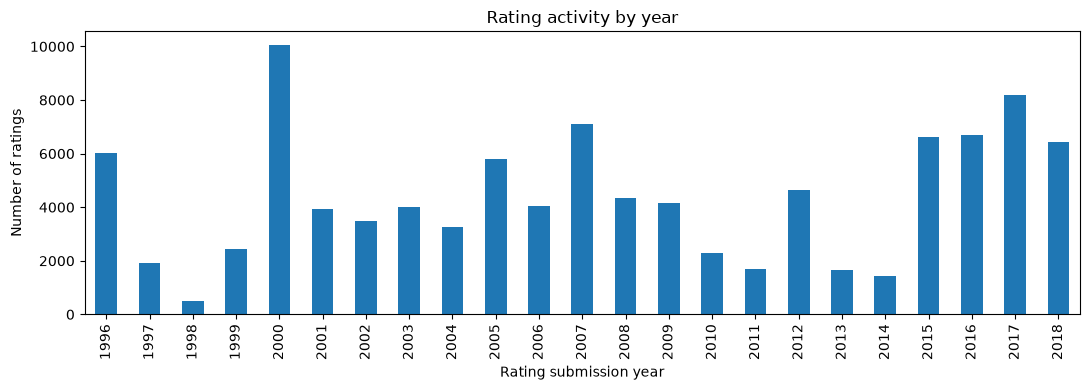

In [19]:
import matplotlib.pyplot as plt

ratings_by_year = (
    ratings_with_movies.resample("YS", on="rated_at")
    .agg(rating_count=("rating", "size"))
)

ratings_by_year.index = ratings_by_year.index.year
ratings_by_year.index.name = "year"

ratings_by_year["percent_of_ratings"] = (
    ratings_by_year["rating_count"]
    / len(ratings_with_movies)
    * 100
)

display(ratings_by_year.round(2))

ax = ratings_by_year["rating_count"].plot(
    kind="bar",
    figsize=(11, 4)
)

ax.set_title("Rating activity by year")
ax.set_xlabel("Rating submission year")
ax.set_ylabel("Number of ratings")

plt.tight_layout()
plt.show()

Divide dataset into training, validation, and test portions using date cutoffs so that the datasets are sized in proportions of .6, .2, .2, respectivley by date.

In [20]:
dates = ratings_with_movies["rated_at"]

train_cutoff = dates.quantile(0.60)
validation_cutoff = dates.quantile(0.80)

train_ratings = ratings_with_movies.loc[
    dates <= train_cutoff
].copy()

validation_ratings = ratings_with_movies.loc[
    (dates > train_cutoff) & (dates <= validation_cutoff)
].copy()

test_ratings = ratings_with_movies.loc[
    dates > validation_cutoff
].copy()

Dataset row sizes and date cutoffs

In [21]:
print("Training rows:", len(train_ratings))
print("Validation rows:", len(validation_ratings))
print("Test rows:", len(test_ratings))

print("Training cutoff:", train_cutoff)
print("Validation cutoff:", validation_cutoff)

Training rows: 60502
Validation rows: 20167
Test rows: 20167
Training cutoff: 2009-11-17 01:21:52+00:00
Validation cutoff: 2016-03-22 08:26:11+00:00


Rating activity varies across years. For example, 2000
contains 9.98% of ratings, compared with 0.50% in 1998. The chronological
splits therefore cover unequal lengths of calendar time.

There are 85,043 distinct timestamps across 100,836 ratings. Shared
timestamps occur among distinct rating records and are retained.

Splitting the data by 60%, 20%, and 20% by date will still achieve the purpose of splitting the data into data sets of sizes 60k/20k/20k by row count.
The main implications of uneven activity are differences in calendar
coverage and the users and movies represented in each period.

In [22]:
validation_known_user = validation_ratings["userId"].isin(
    train_ratings["userId"]
)

validation_known_movie = validation_ratings["movieId"].isin(
    train_ratings["movieId"]
)

In [23]:
print(
    "Validation users with training history:",
    validation_ratings.loc[
        validation_known_user, "userId"
    ].nunique()
)

print(
    "Validation users without training history:",
    validation_ratings.loc[
        ~validation_known_user, "userId"
    ].nunique()
)

Validation users with training history: 25
Validation users without training history: 141


Most of the validation users do not have training history

In [24]:
print(
    "Validation ratings for movies unseen in training:",
    (~validation_known_movie).sum()
)

print(
    "Validation ratings with both user and movie known:",
    (validation_known_user & validation_known_movie).sum()
)

Validation ratings for movies unseen in training: 4784
Validation ratings with both user and movie known: 2041


only 2,041 of 20,167 validation ratings (~ 10%), have both a user and a movie seen during training.
Most validation users have no training history. This is a limitation to keep in mind. Since this is an expirament and learning excerize it is ok for now.

Next we will find the most frequently rated movies in the training ratings data set.
For a new user, this provides a general popularity ranking.
For a returning user, we’ll remove movies they already rated during training.
This is a simple reference that more sophisticated models will need to improve upon.

In [25]:
movie_popularity = (
    train_ratings.groupby("movieId")
    .size()
    .reset_index(name="training_rating_count")
)

movie_popularity.head()

,movieId,training_rating_count
0,1,149
1,2,75
2,3,48
3,4,7
4,5,41


In [26]:
movie_popularity = movie_popularity.merge(
    movies[["movieId", "title"]],
    on="movieId",
    how="left",
    validate="one_to_one"
)

movie_popularity = movie_popularity.sort_values(
    ["training_rating_count", "movieId"],
    ascending=[False, True]
)

print(
    "Training ratings counted:",
    movie_popularity["training_rating_count"].sum()
)

movie_popularity.head(10)

Training ratings counted: 60502


,movieId,training_rating_count,title
257,296,201,Pulp Fiction (1994)
314,356,193,Forrest Gump (1994)
416,480,185,Jurassic Park (1993)
277,318,177,"Shawshank Redemption, The (1994)"
508,593,177,"Silence of the Lambs, The (1991)"
97,110,174,Braveheart (1995)
505,589,166,Terminator 2: Judgment Day (1991)
397,457,160,"Fugitive, The (1993)"
507,592,160,Batman (1989)
611,780,157,Independence Day (a.k.a. ID4) (1996)


Next we can use the popularity ranking in a function that will return the 10 most frequently rated tiltes that that user did not already rank in the training data set.

In [27]:
def recommend_popular(user_id, training_data, popularity_ranking, n=10):
    """Return popular movies the user has not rated in training."""

    rated_movie_ids = training_data.loc[
        training_data["userId"] == user_id,
        "movieId"
    ]

    eligible_movies = popularity_ranking.loc[
        ~popularity_ranking["movieId"].isin(rated_movie_ids)
    ]

    return eligible_movies.head(n).reset_index(drop=True)

In [28]:
user_1_recommendations = recommend_popular(
    user_id=1,
    training_data=train_ratings,
    popularity_ranking=movie_popularity,
    n=10
)

user_1_recommendations

,movieId,training_rating_count,title
0,318,177,"Shawshank Redemption, The (1994)"
1,589,166,Terminator 2: Judgment Day (1991)
2,150,156,Apollo 13 (1995)
3,380,156,True Lies (1994)
4,377,143,Speed (1994)
5,588,137,Aladdin (1992)
6,32,135,Twelve Monkeys (a.k.a. 12 Monkeys) (1995)
7,344,125,Ace Ventura: Pet Detective (1994)
8,165,119,Die Hard: With a Vengeance (1995)
9,364,119,"Lion King, The (1994)"


We can write a function to see what movies are being excluded for user 1

In [29]:
user_1_history = train_ratings.loc[
    train_ratings["userId"] == 1,
    ["movieId", "rating"]
]

excluded_movies = movie_popularity.loc[
    movie_popularity["movieId"].isin(user_1_history["movieId"])
].merge(
    user_1_history,
    on="movieId",
    how="left",
    validate="one_to_one"
)


excluded_movies = excluded_movies[
    ["movieId", "title", "rating", "training_rating_count"]
].reset_index(drop=True)

print("Number of movies excluded:", len(excluded_movies))

excluded_movies


Number of movies excluded: 232


,movieId,title,rating,training_rating_count
0,296,Pulp Fiction (1994),3.0,201
1,356,Forrest Gump (1994),4.0,193
2,480,Jurassic Park (1993),4.0,185
3,593,"Silence of the Lambs, The (1991)",4.0,177
4,110,Braveheart (1995),4.0,174
...,...,...,...,...
227,2654,"Wolf Man, The (1941)",5.0,3
228,2899,Gulliver's Travels (1939),5.0,3
229,3729,Shaft (1971),5.0,3
230,1793,Welcome to Woop-Woop (1997),4.0,2


In [30]:
user_1_recommendations = recommend_popular(
    user_id=1,
    training_data=train_ratings,
    popularity_ranking=movie_popularity,
    n=10
)

print(
    "Excluded movies appearing in recommendations:",
    user_1_recommendations["movieId"].isin(
        excluded_movies["movieId"]
    ).sum()
)

Excluded movies appearing in recommendations: 0


Movies are being excluded form the default popularity recommendation

Select a new user. We will start by defining a positive rating as >= 4 stars.

In [31]:
new_user_id = validation_ratings.loc[
    (~validation_known_user)
    & (validation_ratings["rating"] >= 4.0),
    "userId"
].iloc[0]

print("Example new user:", new_user_id)

Example new user: 2


In [32]:
new_user_recommendations = recommend_popular(
    user_id=new_user_id,
    training_data=train_ratings,
    popularity_ranking=movie_popularity,
    n=10
)

new_user_recommendations

,movieId,training_rating_count,title
0,296,201,Pulp Fiction (1994)
1,356,193,Forrest Gump (1994)
2,480,185,Jurassic Park (1993)
3,318,177,"Shawshank Redemption, The (1994)"
4,593,177,"Silence of the Lambs, The (1991)"
5,110,174,Braveheart (1995)
6,589,166,Terminator 2: Judgment Day (1991)
7,457,160,"Fugitive, The (1993)"
8,592,160,Batman (1989)
9,780,157,Independence Day (a.k.a. ID4) (1996)


Calculate recall@10 for the new user

In [33]:
liked_movie_ids = validation_ratings.loc[
    (validation_ratings["userId"] == new_user_id)
    & (validation_ratings["rating"] >= 4.0),
    "movieId"
]

hits = new_user_recommendations["movieId"].isin(
    liked_movie_ids
).sum()

recall_at_10 = hits / len(liked_movie_ids)

print("Positive validation movies:", len(liked_movie_ids))
print("Hits among recommendations:", hits)
print("Recall@10:", recall_at_10)

Positive validation movies: 19
Hits among recommendations: 0
Recall@10: 0.0


This is testing to see how many movies is the rcommendation function reccomending, based on frequency of ratings, to the user that we can verify are movies that they like based on a rating in the validation ratings data. For this one it is zero: the function is not reccomending any movies we can verify the user likes.  

In [34]:
liked_movies = movies.loc[
    movies["movieId"].isin(liked_movie_ids),
    ["movieId", "title"]
].copy()

liked_movies["in_popularity_ranking"] = liked_movies["movieId"].isin(
    movie_popularity["movieId"]
)

print(
    "Positive movies present in popularity ranking:",
    liked_movies["in_popularity_ranking"].sum(),
    "out of",
    len(liked_movies)
)

liked_movies

Positive movies present in popularity ranking: 9 out of 19


,movieId,title,in_popularity_ranking
291,333,Tommy Boy (1995),True
1284,1704,Good Will Hunting (1997),True
2674,3578,Gladiator (2000),True
4615,6874,Kill Bill: Vol. 1 (2003),True
6253,46970,Talladega Nights: The Ballad of Ricky Bobby (2...,True
6315,48516,"Departed, The (2006)",True
6710,58559,"Dark Knight, The (2008)",True
6801,60756,Step Brothers (2008),True
7010,68157,Inglourious Basterds (2009),True
7258,74458,Shutter Island (2010),False


this shows there were 9 movies that could have been recommended to the user based on popularity (high frequency of rating) but they were too low down on the popularity reccomender list.

In [35]:
validation_positives = validation_ratings.loc[
    validation_ratings["rating"] >= 4.0
].copy()

evaluation_user_ids = validation_positives["userId"].unique()

total_validation_users = validation_ratings["userId"].nunique()

print("Total validation users:", total_validation_users)

print(
    "Users with positive validation ratings:",
    len(evaluation_user_ids)
)

print(
    "Users with no positive validation ratings:",
    total_validation_users - len(evaluation_user_ids)
)

Total validation users: 166
Users with positive validation ratings: 165
Users with no positive validation ratings: 1


Write a function that calculates the recall@10 for all validation users

In [36]:
evaluation_rows = []

for user_id in evaluation_user_ids:
    user_positive_movie_ids = validation_positives.loc[
        validation_positives["userId"] == user_id,
        "movieId"
    ]

    user_recommendations = recommend_popular(
        user_id=user_id,
        training_data=train_ratings,
        popularity_ranking=movie_popularity,
        n=10
    )

    user_hits = user_recommendations["movieId"].isin(
        user_positive_movie_ids
    ).sum()

    user_recall = user_hits / len(user_positive_movie_ids)

    evaluation_rows.append({
        "userId": user_id,
        "positive_movie_count": len(user_positive_movie_ids),
        "hits_at_10": user_hits,
        "recall_at_10": user_recall
    })

popularity_results = pd.DataFrame(evaluation_rows)

popularity_results.head()

,userId,positive_movie_count,hits_at_10,recall_at_10
0,2,19,0,0.000000
1,3,16,0,0.000000
2,10,50,0,0.000000
3,15,6,0,0.000000
4,16,53,1,0.018868


Calculate the average recall@10 among all validation users with positive ratings (1 user had no positive ratings).

In [37]:
print("Users evaluated:", len(popularity_results))

print(
    "Mean Recall@10:",
    popularity_results["recall_at_10"].mean()
)

Users evaluated: 165
Mean Recall@10: 0.039752968874816816


In [38]:
popularity_results["has_training_history"] = (
    popularity_results["userId"].isin(
        train_ratings["userId"]
    )
)

group_summary = (
    popularity_results.groupby("has_training_history")
    .agg(
        users=("userId", "size"),
        mean_recall_at_10=("recall_at_10", "mean")
    )
)

group_summary

,users,mean_recall_at_10
has_training_history,,
False,140,0.041847
True,25,0.028027


### Popularity baseline experiment

I built a simple recommender that ranks movies by their number of training
ratings. It returns the top ten movies after excluding titles the user
already rated during training. The ranking measures popularity and does
not learn individual preferences.

#### Evaluation setup

- Ratings were split chronologically using timestamp quantiles:
  60,502 training rows, 20,167 validation rows, and 20,167 test rows.
- Training ends in November 2009; validation extends through March 2016.
  The test set is reserved for final evaluation.
- A validation rating of 4 stars or higher counts as positive feedback.
- Recall@10 measures the fraction of a user's positive validation movies
  appearing in their ten recommendations.
- Recall was calculated for 165 users and averaged with equal weight per
  user. One additional validation user had no positive ratings and was
  excluded because their recall denominator would be zero.
- Positive movies absent from training remain in the denominator.

#### Validation results

| User group | Users evaluated | Mean Recall@10 |
|---|---:|---:|
| No training history | 140 | 4.18% |
| Has training history | 25 | 2.80% |
| Overall | 165 | 3.98% |

The overall result means that the recommendations recovered an average
of 3.98% of each user's known positive validation movies. Users without
training history account for approximately 85% of those evaluated and
therefore contribute most of the overall average.

#### Findings and limitations

The baseline scored higher for users without training history. This
comparison does not establish that history reduces performance: the
groups contain different users, and previously rated movies are excluded
from returning users' recommendations.

Candidate availability also limits performance. The baseline can only
recommend movies rated during training. For one example user, only nine
of nineteen positive validation movies were present in its candidate
ranking. The remaining ten were absent from training.

Rating activity varies substantially across years. Timestamp quantiles
preserve approximately the intended row proportions, while the splits
cover unequal lengths of calendar time and different users and movies.

Recall@10 depends on the number of positive movies, the ten-item limit,
and candidate availability. The score alone is insufficient to judge
performance relative to other approaches. It also measures recorded
positive feedback; preferences for unrated movies remain unknown.

These results establish a benchmark for evaluating personalized
recommendations under the same evaluation rules.

In [39]:
popularity_results = pd.DataFrame(evaluation_rows)

from pathlib import Path

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

popularity_results.to_csv(
    processed_dir / "popularity_validation_results.csv",
    index=False
)

print("Users evaluated:", len(popularity_results))
print("Mean Recall@10:", popularity_results["recall_at_10"].mean())
print("Saved popularity_validation_results.csv")

Users evaluated: 165
Mean Recall@10: 0.039752968874816816
Saved popularity_validation_results.csv
